# Parallel Batch Extraction & Parquet Output

Dataset-scale feature extraction with `extract_features_from_folder`:

- **`n_jobs`** fans extraction out over worker processes (identical results to serial, deterministic ordering).
- **Parquet output** produces one row per file with named columns (`mfcc_0`, ..., `zcr`) that loads straight into pandas.

Equivalent CLI: `afx <folder> --format parquet --output features.parquet -j 8`


In [1]:
import json
import os
import shutil
import tempfile
import time
from pathlib import Path

import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt

from AFX.batch_extractor import extract_features_from_folder

SR = 16000

## Build a working folder

Up to 12 clips from a configured environmental-sound dataset (Nonspeech7k, ESC-50, UrbanSound8K — via environment variables), otherwise synthesized clips.

In [2]:
import glob

# Environmental-sound dataset roots are passed via environment variables.
# Set any ONE of these before launching Jupyter, e.g.
#   export ESC_50_dataset=/path/to/ESC-50
DATASET_ENV_VARS = ['dataset_nonspeech7k', 'nonspeech7k_dataset',
                    'ESC_50_dataset', 'UrbanSound8K_dataset']

def find_dataset_audio(max_files=None, exts=('.wav', '.ogg', '.flac')):
    """Return audio file paths from the first configured dataset env var
    (empty list if no dataset is configured)."""
    for var in DATASET_ENV_VARS:
        root = os.environ.get(var)
        if root and os.path.isdir(root):
            files = sorted(
                p for ext in exts for p in
                glob.glob(os.path.join(root, '**', '*' + ext), recursive=True)
            )
            if files:
                print(f'Dataset: {var} -> {root} ({len(files)} audio files)')
            return files[:max_files] if max_files else files
    return []

def synth_clip(kind, seconds=1.0, sr=22050, seed=0):
    """Synthesize a simple environmental-sound-like clip (fallback when no
    dataset env var is configured)."""
    rng = np.random.default_rng(seed)
    t = np.arange(int(sr * seconds)) / sr
    if kind == 'tonal':        # bird-chirp-like rising tone
        f = 800 + 600 * t
        sig = 0.6 * np.sin(2 * np.pi * f * t)
    elif kind == 'noisy':      # rain-like broadband noise
        sig = 0.4 * rng.standard_normal(t.size)
    else:                      # engine-like low harmonic stack
        sig = sum(0.3 / k * np.sin(2 * np.pi * 90 * k * t) for k in (1, 2, 3))
    sig = sig + 0.02 * rng.standard_normal(t.size)
    return sig.astype(np.float32)

workdir = Path(tempfile.mkdtemp(prefix='afx_batch_'))
audio_dir = workdir / 'audio'
audio_dir.mkdir()

files = find_dataset_audio(max_files=12)
if len(files) >= 16:
    for f in files:
        shutil.copy(f, audio_dir / os.path.basename(f))
else:
    print('No (large enough) dataset configured - synthesizing 12 clips.')
    kinds = ['tonal', 'noisy', 'harmonic']
    for i in range(12):
        sf.write(audio_dir / f'clip_{i:02d}.wav',
                 synth_clip(kinds[i % 3], seconds=3.0, sr=SR, seed=i), SR)

config = {
    'sample_rate': SR,
    'features': {
        'mfcc': {'n_mfcc': 13, 'frame_size': 1024, 'hop_length': 512},
        'mfcc_delta': {'n_mfcc': 13, 'frame_size': 1024, 'hop_length': 512},
        'melspectrogram': {'n_mels': 64, 'frame_size': 1024, 'hop_length': 512},
        'chroma_stft': {'frame_size': 1024, 'hop_length': 512},
        'spectral_contrast': {'frame_size': 1024, 'hop_length': 512},
        'spectral_centroid': {'frame_size': 1024, 'hop_length': 512},
        'spectral_flatness': {'frame_size': 1024, 'hop_length': 512},
        'sample_entropy': {'frame_size': 2048, 'hop_length': 4096},
        'zcr': {'frame_size': 1024, 'hop_length': 512},
    },
    'aggregation': 'mean',
}
config_path = workdir / 'config.json'
config_path.write_text(json.dumps(config, indent=2))
print(f'{len(list(audio_dir.iterdir()))} files in {audio_dir}')

Dataset: nonspeech7k_dataset -> /tmp/fake_ns7k (4 audio files)
No (large enough) dataset configured - synthesizing 12 clips.
12 files in /sessions/laughing-inspiring-gates/tmp/afx_batch_q_pqni1j/audio


## Serial vs parallel

[1/12] Processing clip_00.wav
[2/12] Processing clip_01.wav
[3/12] Processing clip_02.wav
[4/12] Processing clip_03.wav
[5/12] Processing clip_04.wav
[6/12] Processing clip_05.wav
[7/12] Processing clip_06.wav
[8/12] Processing clip_07.wav
[9/12] Processing clip_08.wav
[10/12] Processing clip_09.wav
[11/12] Processing clip_10.wav
[12/12] Processing clip_11.wav
Processing 12 file(s) with 2 workers
[1/12] Processed clip_01.wav
[2/12] Processed clip_00.wav
[3/12] Processed clip_03.wav
[4/12] Processed clip_02.wav
[5/12] Processed clip_04.wav
[6/12] Processed clip_05.wav
[7/12] Processed clip_06.wav
[8/12] Processed clip_07.wav
[9/12] Processed clip_08.wav
[10/12] Processed clip_09.wav
[11/12] Processed clip_10.wav
[12/12] Processed clip_11.wav
serial:   8.30 s
parallel: 5.82 s  (n_jobs=2, speedup x1.42)
parallel output identical to serial: OK


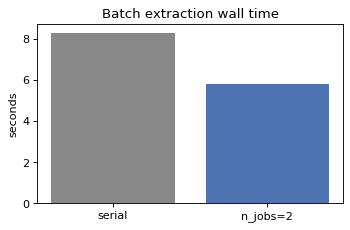

In [3]:
def timed_run(n_jobs, tag):
    out = workdir / f'features_{tag}.json'
    t0 = time.perf_counter()
    res = extract_features_from_folder(
        str(audio_dir), str(config_path), str(out),
        save_format='json', n_jobs=n_jobs,
    )
    dt = time.perf_counter() - t0
    return res, dt

n_workers = os.cpu_count()
res_serial, t_serial = timed_run(1, 'serial')
res_parallel, t_parallel = timed_run(0, 'parallel')   # 0 = all cores

print(f'serial:   {t_serial:.2f} s')
print(f'parallel: {t_parallel:.2f} s  (n_jobs={n_workers}, '
      f'speedup x{t_serial / t_parallel:.2f})')

# Parallel results are identical to serial, in identical order
assert list(res_serial) == list(res_parallel)
for k in res_serial:
    for feat in res_serial[k]:
        np.testing.assert_allclose(res_serial[k][feat], res_parallel[k][feat])
print('parallel output identical to serial: OK')

plt.figure(figsize=(4.5, 3))
plt.bar(['serial', f'n_jobs={n_workers}'], [t_serial, t_parallel],
        color=['#888', '#4C72B0'])
plt.ylabel('seconds')
plt.title('Batch extraction wall time')
plt.tight_layout()

> Speedups grow with dataset size — worker startup is a fixed cost, so on thousands of files the scaling approaches the core count. `n_jobs=0` uses all available cores.

## Parquet output

One row per file, vector features expanded to named columns. Requires `pip install "AFX[parquet]"`; this cell falls back to CSV when pyarrow is unavailable.

In [4]:
try:
    import pyarrow  # noqa: F401
    out_path = workdir / 'features.parquet'
    extract_features_from_folder(
        str(audio_dir), str(config_path), str(out_path),
        save_format='parquet', n_jobs=0,
    )
    df = pd.read_parquet(out_path)
except ImportError:
    print('pyarrow not installed - falling back to CSV.')
    out_path = workdir / 'features.csv'
    extract_features_from_folder(
        str(audio_dir), str(config_path), str(out_path),
        save_format='csv', n_jobs=0,
    )
    df = pd.read_csv(out_path, index_col='file')

print(out_path.name, df.shape)
df.head()

Processing 12 file(s) with 2 workers
[1/12] Processed clip_01.wav
[2/12] Processed clip_00.wav
[3/12] Processed clip_02.wav
[4/12] Processed clip_03.wav
[5/12] Processed clip_04.wav
[6/12] Processed clip_05.wav
[7/12] Processed clip_06.wav
[8/12] Processed clip_07.wav
[9/12] Processed clip_08.wav
[10/12] Processed clip_09.wav
[11/12] Processed clip_10.wav
[12/12] Processed clip_11.wav
features.parquet (12, 113)


,mfcc_0,mfcc_1,mfcc_2,mfcc_3,mfcc_4,mfcc_5,mfcc_6,mfcc_7,mfcc_8,mfcc_9,mfcc_10,mfcc_11,mfcc_12,mfcc_delta_0,mfcc_delta_1,mfcc_delta_2,mfcc_delta_3,mfcc_delta_4,mfcc_delta_5,mfcc_delta_6,mfcc_delta_7,mfcc_delta_8,mfcc_delta_9,mfcc_delta_10,mfcc_delta_11,mfcc_delta_12,melspectrogram_0,melspectrogram_1,melspectrogram_2,melspectrogram_3,melspectrogram_4,melspectrogram_5,melspectrogram_6,melspectrogram_7,melspectrogram_8,melspectrogram_9,melspectrogram_10,melspectrogram_11,melspectrogram_12,melspectrogram_13,...,melspectrogram_47,melspectrogram_48,melspectrogram_49,melspectrogram_50,melspectrogram_51,melspectrogram_52,melspectrogram_53,melspectrogram_54,melspectrogram_55,melspectrogram_56,melspectrogram_57,melspectrogram_58,melspectrogram_59,melspectrogram_60,melspectrogram_61,melspectrogram_62,melspectrogram_63,chroma_stft_0,chroma_stft_1,chroma_stft_2,chroma_stft_3,chroma_stft_4,chroma_stft_5,chroma_stft_6,chroma_stft_7,chroma_stft_8,chroma_stft_9,chroma_stft_10,chroma_stft_11,spectral_contrast_0,spectral_contrast_1,spectral_contrast_2,spectral_contrast_3,spectral_contrast_4,spectral_contrast_5,spectral_contrast_6,spectral_centroid,spectral_flatness,sample_entropy,zcr
file,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
clip_00.wav,-224.517428,-8.838489,-9.841835,3.567990,-1.304681,2.362541,1.949759,-0.755643,1.372628,-1.993635,0.153366,0.928924,0.497414,-0.215740,-0.343098,0.130339,0.367596,0.206373,0.209549,-0.382080,-0.396703,-0.208246,0.022486,0.417895,0.151320,0.100717,0.013758,0.012001,0.012026,0.012423,0.012814,0.012125,0.012727,0.014018,0.014540,0.014617,0.016886,0.019173,0.021684,0.033612,...,9.800413,9.828292,9.834791,9.816578,8.339491,1.013681,0.009939,0.009891,0.010083,0.010096,0.010272,0.009490,0.009587,0.009761,0.009415,0.009782,0.009838,0.092621,0.080030,0.055290,0.061043,0.068664,0.078106,0.070362,0.083722,0.090256,0.096473,0.108365,0.115069,19.297807,18.086145,21.795538,36.272656,46.062395,40.386890,27.297282,3016.223074,0.001479,0.210324,0.323186
clip_01.wav,54.953320,-5.573025,0.766546,0.356845,-0.000261,0.134447,-0.221386,-0.365691,-0.694238,-0.893145,-0.879981,-0.139707,0.392489,-0.079665,-0.050648,0.042286,0.035775,-0.058155,-0.091327,-0.039394,0.001688,0.089417,0.024480,-0.026441,0.012897,-0.001842,3.519944,3.483544,3.507502,3.582056,3.860134,3.993792,4.324629,3.889102,3.570879,3.779921,4.065357,3.617936,3.658019,3.509448,...,3.719069,4.050918,3.770524,3.840003,3.916179,3.904121,3.866410,4.096810,3.883135,3.736527,3.821793,3.652654,3.886176,4.026680,3.829835,3.694269,3.698452,0.054702,0.067947,0.063323,0.071273,0.076182,0.085272,0.080604,0.089692,0.095843,0.099294,0.109364,0.106506,17.196508,17.901372,22.457395,25.610464,26.208983,26.929191,26.666961,4012.886751,0.561714,2.185649,0.503081
clip_02.wav,-204.810770,40.609476,43.479578,40.018496,34.436589,28.595436,22.690211,14.716855,8.847823,2.641970,-3.281546,-6.728996,-9.897251,0.002493,-0.017415,-0.042221,0.044323,-0.048740,-0.025913,0.010040,-0.007114,0.068823,0.069166,0.031554,-0.033257,-0.055959,18.973810,163.558145,14.394866,39.043180,5.640341,16.257335,0.480892,0.013773,0.011583,0.012006,0.011047,0.010032,0.009714,0.009383,...,0.010281,0.009770,0.009461,0.009539,0.009540,0.009177,0.009460,0.009523,0.009794,0.009361,0.009391,0.009714,0.009852,0.009754,0.009847,0.009736,0.009862,0.072174,0.065431,0.027362,0.150994,0.029275,0.100842,0.261528,0.034914,0.050563,0.093629,0.042728,0.070560,53.705069,47.180571,21.376018,26.258595,25.472035,27.133087,26.939457,1620.230677,0.004480,0.281850,0.019975
clip_03.wav,-224.763250,-8.779848,-9.739437,3.756862,-2.153848,1.830328,2.194496,-0.708180,2.731466,-2.105229,0.037135,-0.124949,-0.725379,-0.159924,-0.371923,0.054626,0.274835,0.201876,0.193944,-0.310593,-0.196523,-0.112723,-0.037479,0.451785,0.215347,0.155290,0.012724,0.012350,0.013063,0.012362,0.012501,0.012425,0.011578,0.013509,0.013591,0.014837,0.015709,0.018684,0.025235,0.033911,...,9.814162,9.838145,9.790479,9.840570,8.299198,

In [5]:
# Feature table ready for ML: named columns, one row per file
df[['mfcc_0', 'mfcc_1', 'spectral_centroid', 'spectral_flatness',
    'zcr']].describe().T[['mean', 'std', 'min', 'max']]

,mean,std,min,max
mfcc_0,-124.571344,133.335088,-224.763250,56.098127
mfcc_1,8.775793,23.385348,-9.243167,40.609476
spectral_centroid,2881.310746,1019.882317,1620.230677,4012.886751
spectral_flatness,0.188382,0.273846,0.001462,0.561714
zcr,0.281308,0.207706,0.019062,0.503081


## Notes

- Failed files never poison the batch: errors are collected into `<output>.errors.json` and reported, while successful rows are written normally.
- The same options are exposed on the CLI: `--jobs/-j`, `--format parquet`, `--features`, `--aggregation`, `--normalize`.
- For downstream training, `pd.read_parquet(...)` + `df.to_numpy()` (or polars/duckdb) makes the extracted table immediately usable.

In [6]:
# Clean up the temporary working folder
shutil.rmtree(workdir)
print('removed', workdir)

removed /sessions/laughing-inspiring-gates/tmp/afx_batch_q_pqni1j
